# Quy trình Xây dựng Hệ thống Giám sát & Phát hiện Té ngã từ A đến Z (`detect_v3`)

Notebook này tái hiện **trọn vẹn quy trình kỹ thuật từ A đến Z** để xây dựng hệ thống phát hiện té ngã đa người, đa góc nhìn kết hợp **YOLOv8n-Pose + 66 Đặc trưng Động học + FallNet (BiLSTM) / FallTransformer (Self-Attention) + AlertStateMachine + Edge IoT (ESP32 & Telegram 10s)**.

### Lộ trình 8 bước trong Notebook
1. **Khởi tạo môi trường & Kiểm tra cấu trúc dự án (`detect_v3`)**
2. **Nạp 6 nguồn dữ liệu `.npz` & Kiểm chứng chống rò rỉ dữ liệu (`Zero Data Leakage`)**
3. **Tầng 1 (YOLO + 7 Bộ lọc Giải phẫu + `PoseTracker`):** Thực nghiệm trích xuất khung xương trên video thực tế
4. **Tầng 2 (`window_features` 66 chiều & `augment_window`):** Trực quan hóa quỹ đạo động học `ADL` vs. `FALL`
5. **Kiến trúc Học sâu (`FallNet` BiLSTM & `FallTransformer`) & Quy trình Huấn luyện (`2_train.py` + Hard-Negative Mining)**
6. **Đánh giá Định lượng Độc lập (Window-level & Event-level) + Ma trận nhầm lẫn**
7. **Mô phỏng Máy trạng thái `AlertStateMachine` & Kiểm thử Video Thực địa (`4_realtime.py`)**
8. **Benchmark tốc độ CPU, Kiến trúc giao tiếp Edge IoT (`Raspberry Pi / PC ↔ ESP32 ↔ Flask ↔ Telegram`) & Tổng kết**

In [1]:
import os
import sys
import time
import platform
from pathlib import Path
from collections import Counter, defaultdict

import cv2
import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Dam bao chay tu thu muc goc DO_AN hoac thu muc con detect_v3
HERE = Path.cwd().resolve()
ROOT = HERE if (HERE / "detect_v3").exists() else HERE.parent
V3_DIR = ROOT / "detect_v3"
if str(V3_DIR) not in sys.path:
    sys.path.insert(0, str(V3_DIR))

from fall_common import (
    CLASS_NAMES, NORMAL, SIT, LIE, FALL,
    GRID_HZ, SEQ_STEPS, FEAT_DIM, INFER_IMGSZ, INFER_CONF, SKELETON,
    FallNet, FallTransformer, AlertStateMachine, PoseTracker,
    extract_all_persons, load_model, window_features,
)
from fall_data import (
    WindowDataset, augment_window, confusion, load_sequences,
    make_frozen_items, make_items, predict, report, split_seqs, window_indices, FIRST_END, BASE_STEP
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"He dieu hanh : {platform.system()} {platform.release()} | CPU: {os.cpu_count()} luong")
print(f"Python       : {sys.version.split()[0]} | PyTorch: {torch.__version__} | Device: {device}")
print(f"OpenCV       : {cv2.__version__}")
print(f"Thu muc goc  : {ROOT}")

models_dir = V3_DIR / "models"
print("\nCac file trong so hien co trong detect_v3/models/:")
for p in sorted(models_dir.glob("*.pt*")):
    print(f"  - {p.name:24s} ({p.stat().st_size / 1024:.1f} KB)")

He dieu hanh : Windows 11 | CPU: 32 luong
Python       : 3.14.4 | PyTorch: 2.15.0+cpu | Device: cpu
OpenCV       : 5.0.0
Thu muc goc  : D:\Education_Material\Addition\SMLab\DO_AN

Cac file trong so hien co trong detect_v3/models/:
  - fall_net.pth             (662.0 KB)
  - fall_net_v3.pth          (465.5 KB)
  - fall_net_v3_best.pth     (1136.4 KB)
  - fall_net_v3_lstm.pth     (662.0 KB)
  - fall_net_v3_opt.pth      (662.0 KB)
  - fall_net_v3_tfm.pth      (465.7 KB)
  - yolov8n-pose.pt          (6672.5 KB)


## Phần A. Lịch sử Tiến hóa & Quy trình Dữ liệu Đa miền (`Zero Data Leakage`)

Trước khi hình thành kiến trúc `detect_v3`, dự án đã trải qua 3 bước tiến hóa:
- **Giai đoạn 1 (`fall_detect_new/`):** Dùng `YOLOv8n` phân loại 3 lớp tĩnh (`normal`, `fall`, `warning`) trên từng ảnh đơn lẻ. Lệnh `random.shuffle` cấp khung hình trong `make_yolo_3class.py` gây **rò rỉ dữ liệu khung hình liền kề** và vùng nền (`background`) gây báo nhầm tới 22–49%.
- **Giai đoạn 2 (`fall_pose_v2/`):** Chuyển sang trích xuất 17 khớp COCO bằng `YOLOv8n-pose` → chuỗi 30 bước × 66 chiều → `FallNet`/`FallTransformer` 4 lớp (`normal`, `sit`, `lie`, `fall`), giải quyết rò rỉ dữ liệu nhưng mới hỗ trợ 1 người (`select_person`) và thiếu góc camera CCTV trên cao.
- **Giai đoạn 3 (`detect_v3/` — Phiên bản hiện tại):** Hợp nhất **6 nguồn dữ liệu đa góc nhìn**, nâng cấp đa người (`extract_all_persons` + 7 bộ lọc giải phẫu + `PoseTracker`), áp dụng **Hard-Negative Mining**, **khóa chống ngồi nhanh** và kết nối **ESP32 + Flask + Telegram 10s**.

### Lệnh trích xuất bộ nhớ đệm `.npz` từ dữ liệu thô (khi tạo mới từ đầu)
```bash
python detect_v3/1_extract_pose_cache.py           # URFD -> detect_v3/cache/
python detect_v3/download_fallvision.py            # Tai FallVision CSV
python detect_v3/convert_fallvision_to_cache.py    # FallVision -> detect_v3/fallvision_cache/
python detect_v3/prepare_multicam_data.py          # Multiple Cameras Fall (8 goc tran) -> detect_v3/mc_cache/
python detect_v3/prepare_gmdcsa24_data.py          # GMDCSA24 (s1..s4) -> detect_v3/gmd_cache/
python detect_v3/prepare_cctv_data.py              # CCTV Incident Static -> detect_v3/own_data/
python detect_v3/import_own_videos.py              # Video tu quay webcam/IMOU -> detect_v3/own_data/
```

Tong chuoi da nap: 6,250 | Tong frames: 870,062
Train: 6,163 chuoi (5,910 nhom) | Val: 87 chuoi (16 nhom)
Kiem tra Zero Data Leakage (Train_groups & Val_groups): 0 nhom trung lap -> AN TOAN!

Nguon du lieu        | Train Chuoi | Train Frames | Val Chuoi | Val Frames
--------------------------------------------------------------------------
URFD                 |          31 |        4,359 |        10 |      1,416
FallVision           |       5,683 |      552,590 |         0 |          0
MC-Fall (8 cam)      |         152 |      197,543 |        40 |     63,596
GMDCSA24             |         123 |       25,544 |        37 |      8,628
CCTV Static          |         121 |        5,445 |         0 |          0
User Own Recorded    |          53 |       10,941 |         0 |          0

Thong ke cua so truot 2.0s @ 15Hz:
  Train Real Windows   : {'normal': 35864, 'sit': 35508, 'lie': 27325, 'fall': 30282} | Tong=128,979
  Train Frozen Windows : {'normal': 19446, 'sit': 212887, 'lie': 140106

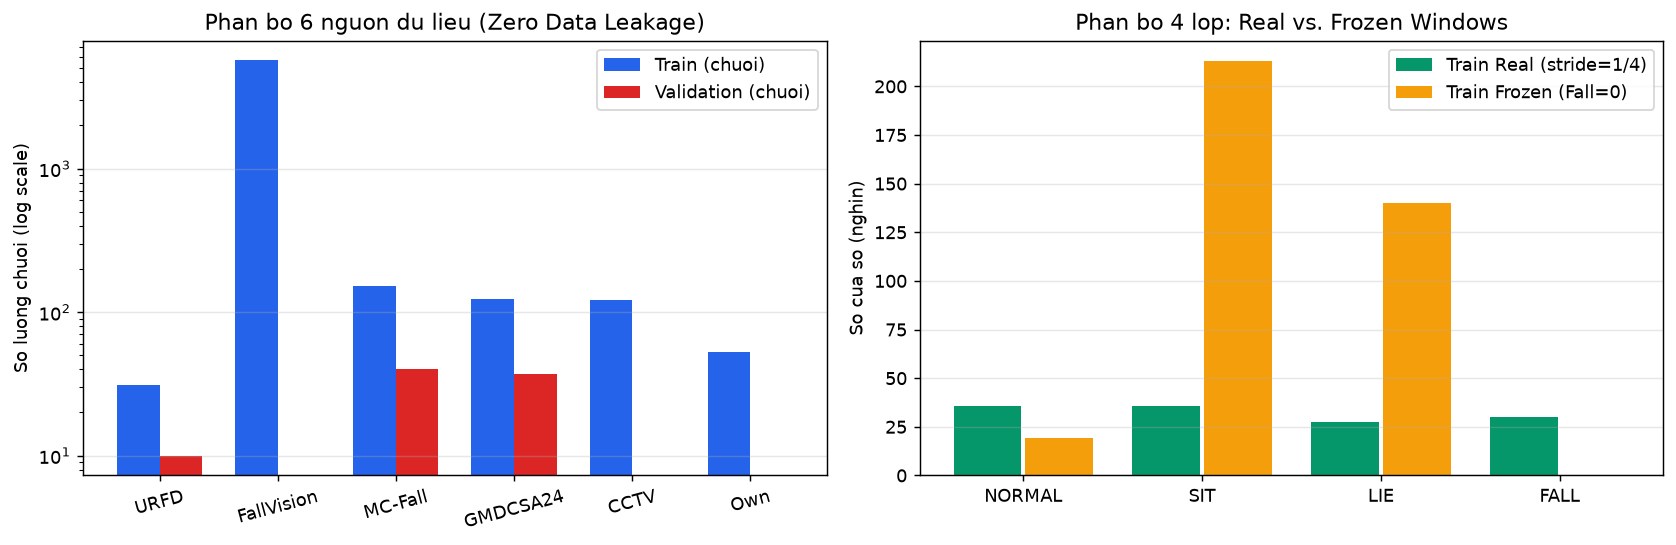

In [2]:
seqs = load_sequences(
    V3_DIR / "cache",
    ROOT / "fall_detect_new" / "labels" / "train",
    V3_DIR / "own_data",
    fv_dir=V3_DIR / "fallvision_cache",
    mc_dir=V3_DIR / "mc_cache",
    gmd_dir=V3_DIR / "gmd_cache",
    verbose=False,
)
tr_seqs, va_seqs = split_seqs(seqs, "fixed")

# Kiem chung tuyet doi Zero Data Leakage theo NHOM su kien / doi tuong / camera
tr_groups = {s.group for s in tr_seqs}
va_groups = {s.group for s in va_seqs}
leak = tr_groups & va_groups
assert len(leak) == 0, f"Phat hien Data Leakage: {leak}"

def source_label(s):
    if s.name.startswith("fv_"): return "FallVision"
    if s.kind in ("mc_fall", "mc_adl"): return "MC-Fall (8 cam)"
    if s.kind in ("gmd_fall", "gmd_adl"): return "GMDCSA24"
    if s.kind == "own":
        return "CCTV Static" if s.name.startswith("own-cctv_") else "User Own Recorded"
    return "URFD"

src_order = ["URFD", "FallVision", "MC-Fall (8 cam)", "GMDCSA24", "CCTV Static", "User Own Recorded"]
print(f"Tong chuoi da nap: {len(seqs):,} | Tong frames: {sum(len(s.phase) for s in seqs):,}")
print(f"Train: {len(tr_seqs):,} chuoi ({len(tr_groups):,} nhom) | Val: {len(va_seqs)} chuoi ({len(va_groups)} nhom)")
print(f"Kiem tra Zero Data Leakage (Train_groups & Val_groups): {len(leak)} nhom trung lap -> AN TOAN!\n")

print(f"{'Nguon du lieu':20s} | {'Train Chuoi':>11s} | {'Train Frames':>12s} | {'Val Chuoi':>9s} | {'Val Frames':>10s}")
print("-" * 74)
tr_counts, va_counts = [], []
for src in src_order:
    t_sub = [s for s in tr_seqs if source_label(s) == src]
    v_sub = [s for s in va_seqs if source_label(s) == src]
    tr_counts.append(len(t_sub))
    va_counts.append(len(v_sub))
    print(f"{src:20s} | {len(t_sub):11,d} | {sum(len(s.phase) for s in t_sub):12,d} | {len(v_sub):9,d} | {sum(len(s.phase) for s in v_sub):10,d}")

# Thong ke cua so truot (2.0s @ 15Hz) giua Cua so thuc vs Frozen Windows
from fall_data import label_window
real_other = [s for s in tr_seqs if not s.name.startswith("fv_")]
real_fv = [s for s in tr_seqs if s.name.startswith("fv_")]
items_real = []
idx_map = {id(s): i for i, s in enumerate(tr_seqs)}
for s in real_other:
    si = idx_map[id(s)]
    for e in range(FIRST_END, len(s.phase), 1):
        lab = label_window(s.phase[window_indices(e, BASE_STEP)], s.present[window_indices(e, BASE_STEP)])
        if lab != -1:
            items_real.append((si, e, lab, 0))
for s in real_fv:
    si = idx_map[id(s)]
    for e in range(FIRST_END, len(s.phase), 4):
        lab = label_window(s.phase[window_indices(e, BASE_STEP)], s.present[window_indices(e, BASE_STEP)])
        if lab != -1:
            items_real.append((si, e, lab, 0))

items_fro = make_frozen_items(tr_seqs, normal_every=8)
items_va = make_items(va_seqs, stride=3)

c_real = Counter(it[2] for it in items_real)
c_fro = Counter(it[2] for it in items_fro)
c_va = Counter(it[2] for it in items_va)

print("\nThong ke cua so truot 2.0s @ 15Hz:")
print("  Train Real Windows   :", {CLASS_NAMES[k]: c_real[k] for k in range(4)}, f"| Tong={len(items_real):,}")
print("  Train Frozen Windows :", {CLASS_NAMES[k]: c_fro[k] for k in range(4)}, f"| Tong={len(items_fro):,}")
print("  Val Windows (stride3):", {CLASS_NAMES[k]: c_va[k] for k in range(4)}, f"| Tong={len(items_va):,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
x = np.arange(len(src_order))
axes[0].bar(x - 0.18, tr_counts, width=0.36, label="Train (chuoi)", color="#2563eb")
axes[0].bar(x + 0.18, [max(v, 0) for v in va_counts], width=0.36, label="Validation (chuoi)", color="#dc2626")
axes[0].set_yscale("log")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["URFD", "FallVision", "MC-Fall", "GMDCSA24", "CCTV", "Own"], rotation=15)
axes[0].set_ylabel("So luong chuoi (log scale)")
axes[0].set_title("Phan bo 6 nguon du lieu (Zero Data Leakage)")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

xc = np.arange(4)
axes[1].bar(xc - 0.2, [c_real[k] / 1000 for k in range(4)], width=0.38, label="Train Real (stride=1/4)", color="#059669")
axes[1].bar(xc + 0.2, [c_fro[k] / 1000 for k in range(4)], width=0.38, label="Train Frozen (Fall=0)", color="#f59e0b")
axes[1].set_xticks(xc)
axes[1].set_xticklabels([c.upper() for c in CLASS_NAMES])
axes[1].set_ylabel("So cua so (nghin)")
axes[1].set_title("Phan bo 4 lop: Real vs. Frozen Windows")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Phần B. Giai đoạn 1 — `YOLOv8n-pose`, 7 Bộ lọc Giải phẫu & Theo dõi Đa mục tiêu (`PoseTracker`)

Trên camera CCTV gắn trần ngoài đời thực, người ở xa hoặc đang nằm ngang có diện tích nhỏ và bị `YOLOv8n-pose` chấm độ tin cậy khung bao thấp. Nếu giữ `conf=0.25` như `v2`, hệ thống sẽ bỏ sót nạn nhân. Vì vậy `detect_v3` giải quyết bằng 2 bước kết hợp trong `detect_v3/fall_common.py`:
1. **Tăng độ nhạy đầu vào:** Dùng `INFER_IMGSZ = 640` và hạ ngưỡng `INFER_CONF = 0.08` để không bỏ sót người nằm xa.
2. **Hậu lọc nghiêm ngặt bằng `extract_all_persons()`:** Áp dụng **7 quy tắc giải phẫu** (diện tích box `0.005–0.85`, độ trải khớp `>= 28 px`, `>= 5` khớp `conf >= 0.30`, độ tin cậy TB `>= 0.18`, `>= 2` khớp thân trên cốt lõi `[0, 5, 6, 11, 12]`, tỷ lệ `0.16 <= w/h <= 6.0`, tỷ lệ trải dài `>= 0.30`, diện tích khớp cho box nằm `conf < 0.45`) kèm **Containment/Keypoint-Overlap NMS** để triệt tiêu bàn ghế, thùng carton, xe máy tạo khớp giả.
3. **Theo dõi đa người `PoseTracker`:** Gán `track_id` độc lập qua `0.5 * IoU + 0.5 * proximity`, giữ dấu khi ngã nhanh (`max_missed_s = 1.2s`).

Video kiem thu: 03.mp4 (1280x720, frame 75)
So detection tho o conf=0.08: 2 -> Sau 7 bo loc giai phau & NMS: 1 nguoi hop le


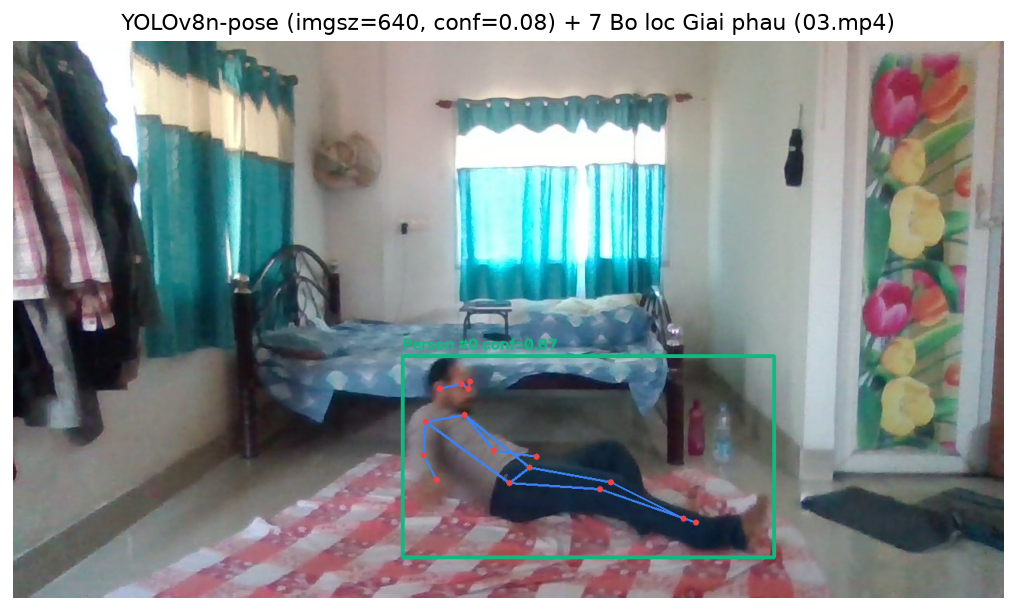

In [3]:
from ultralytics import YOLO

pose_weights = ROOT / "yolov8n-pose.pt"
if not pose_weights.exists():
    pose_weights = V3_DIR / "models" / "yolov8n-pose.pt"
yolo_model = YOLO(str(pose_weights) if pose_weights.exists() else "yolov8n-pose.pt")

demo_vid = None
for cand in [V3_DIR / "03.mp4", V3_DIR / "cam5.mp4", V3_DIR / "test_1.mp4"]:
    if cand.exists():
        demo_vid = cand
        break

if demo_vid is not None:
    cap = cv2.VideoCapture(str(demo_vid))
    total_f = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 100)
    target_f = min(int(total_f * 0.45), total_f - 1)
    cap.set(cv2.CAP_PROP_POS_FRAMES, target_f)
    ok, frame = cap.read()
    cap.release()
    H, W = frame.shape[:2]
    res = yolo_model.predict(frame, imgsz=INFER_IMGSZ, conf=INFER_CONF, verbose=False)[0]
    raw_n = len(res.boxes) if res.boxes is not None else 0
    valid_persons = extract_all_persons(res, W, H)
    print(f"Video kiem thu: {demo_vid.name} ({W}x{H}, frame {target_f})")
    print(f"So detection tho o conf={INFER_CONF}: {raw_n} -> Sau 7 bo loc giai phau & NMS: {len(valid_persons)} nguoi hop le")

    vis = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB).copy()
    for idx, (kp, kc, bx, bc) in enumerate(valid_persons):
        x1, y1, x2, y2 = [int(v) for v in bx]
        cv2.rectangle(vis, (x1, y1), (x2, y2), (16, 185, 129), 3)
        cv2.putText(vis, f"Person #{idx} conf={bc:.2f}", (x1, max(24, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (16, 185, 129), 2)
        for a, b in SKELETON:
            if kc[a] >= 0.30 and kc[b] >= 0.30:
                cv2.line(vis, tuple(kp[a].astype(int)), tuple(kp[b].astype(int)), (59, 130, 246), 2)
        for j in range(17):
            if kc[j] >= 0.30:
                cv2.circle(vis, tuple(kp[j].astype(int)), 4, (239, 68, 68), -1)

    plt.figure(figsize=(8.5, 4.8))
    plt.imshow(vis)
    plt.axis("off")
    plt.title(f"YOLOv8n-pose (imgsz={INFER_IMGSZ}, conf={INFER_CONF}) + 7 Bo loc Giai phau ({demo_vid.name})")
    plt.tight_layout()
    plt.show()
else:
    print("Khong tim thay video .mp4 local -> ve minh hoa khung xuong tu chuoi Validation (.npz)")
    s_ex = [s for s in va_seqs if s.kind == "fall"][0]
    fi = min(s_ex.fall_start + 8, len(s_ex.kpts) - 1)
    kp, kc, bx = s_ex.kpts[fi], s_ex.kconf[fi], s_ex.box[fi]
    plt.figure(figsize=(5.5, 4.2))
    for a, b in SKELETON:
        if kc[a] >= 0.30 and kc[b] >= 0.30:
            plt.plot([kp[a, 0], kp[b, 0]], [kp[a, 1], kp[b, 1]], "b-", lw=2)
    plt.scatter(kp[kc >= 0.30, 0], kp[kc >= 0.30, 1], c="r", s=30)
    plt.gca().invert_yaxis()
    plt.title(f"Skeleton tu tap Val: {s_ex.name} (frame {fi})")
    plt.tight_layout()
    plt.show()

## Phần C. Giai đoạn 2 — Đặc trưng Hình học–Động học 66 Chiều (`window_features`) & Augmentation

Thay vì dùng tọa độ pixel thô phụ thuộc khoảng cách đứng và độ phân giải camera, mỗi đối tượng `PersonTrack` được tái lấy mẫu về tần số chuẩn **`GRID_HZ = 15.0 Hz`**, độ dài **`SEQ_STEPS = 30` bước (2,0 giây)** và biến đổi qua hàm `window_features()` thành tensor **`X ∈ R^(30×66)`**:
- `0..33` (34 chiều): Tọa độ 17 khớp chuẩn hóa `(kp - [cx, cy]) / max(bw, bh)` (nếu `kconf >= 0.30`).
- `34..50` (17 chiều): Cờ hiển thị nhị phân (`visibility`).
- `51` (1 chiều): Cờ hiện diện người (`present`).
- `52..60` (9 chiều): Vị trí & kích thước chuẩn hóa theo `s_ref = median(long_side)`, log tỷ lệ khung bao `clip(ln(W/H), -2, 2)`, góc trục vai–hông `sin(θ), cos(θ)` và `axis_ok`.
- `61..65` (5 chiều): Vận tốc sai phân bậc 1 nhân hệ số `5.0`: `d(y1r), d(y2r), d(bhr), d(cos θ), d(ln(W/H))`.

Ngoài ra, trong quá trình huấn luyện, hàm `augment_window()` biến đổi trực tiếp trên chuỗi khung xương: lật ngang kèm hoán đổi đúng 8 cặp khớp trái–phải, xoay camera nghiêng `N(0, 5°)` cắt trong `[-12°, +12°]`, nhiễu Gaussian `σ = 0.006 × L`, che khuất 6 khớp thân dưới (`upper-body masking`, `p=0.30`), làm rơi 1–3 frame YOLO và co giãn tốc độ `0.75–1.30×`.

Kiem tra tensor dau ra window_features(): shape=(30, 66), dtype=float32
Sai khac trung binh sau augment_window(): 0.0115 (van giu dung tensor (30, 66))


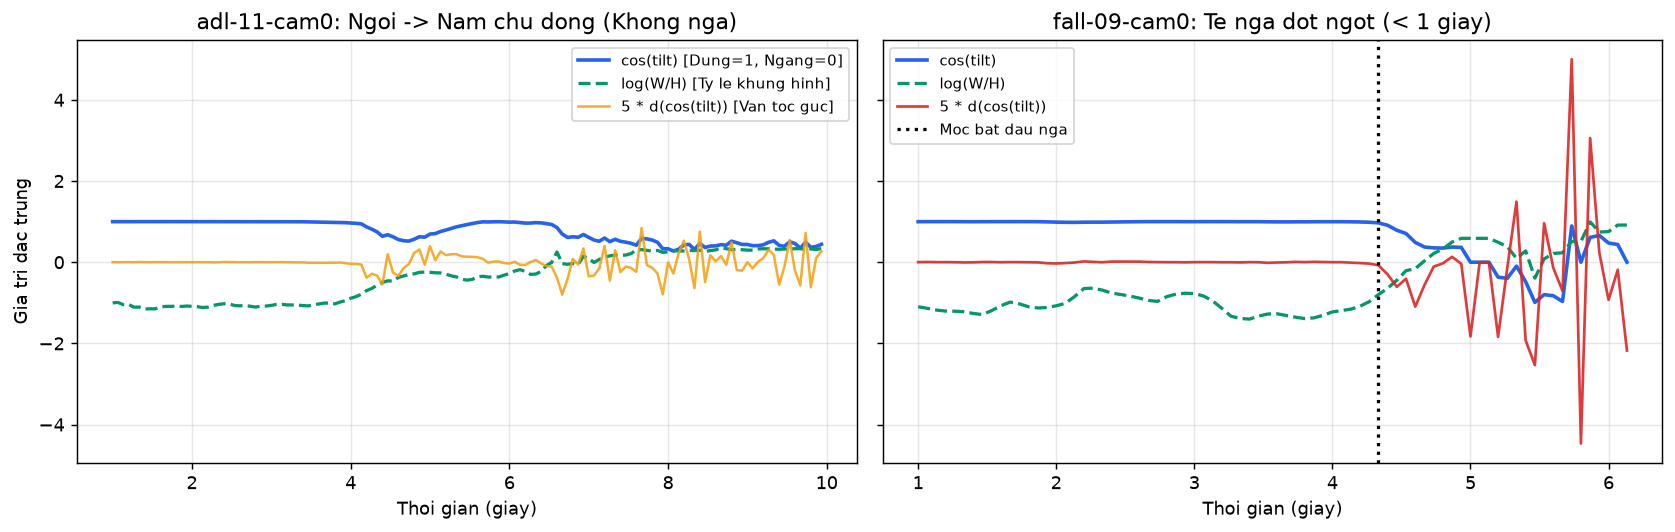

In [4]:
seq_map = {s.name: s for s in seqs}
s_adl = seq_map.get("adl-11-cam0", [s for s in va_seqs if s.kind == "adl"][0])
s_fall = seq_map.get("fall-09-cam0", [s for s in va_seqs if s.kind == "fall"][0])

def trace_features(s):
    ends = list(range(FIRST_END, len(s.phase), 2))
    ts = np.array([e / 30.0 for e in ends])
    feats = np.stack([window_features(s.kpts[i], s.kconf[i], s.box[i], s.present[i])[-1]
                      for i in (window_indices(e, BASE_STEP) for e in ends)])
    # feats[:, 57] = log(W/H), feats[:, 59] = cos(theta), feats[:, 64] = d(cos theta)
    return ts, feats

t_adl, f_adl = trace_features(s_adl)
t_fall, f_fall = trace_features(s_fall)

# Minh hoa augment_window() tren 1 cua so mau
idx0 = window_indices(min(len(s_fall.phase) - 1, max(FIRST_END, s_fall.fall_start + 5)), BASE_STEP)
rng_aug = np.random.default_rng(42)
kp_a, kc_a, bx_a, pr_a = augment_window(s_fall.kpts[idx0], s_fall.kconf[idx0], s_fall.box[idx0], s_fall.present[idx0], s_fall.W, s_fall.H, rng_aug)
x_orig = window_features(s_fall.kpts[idx0], s_fall.kconf[idx0], s_fall.box[idx0], s_fall.present[idx0])
x_aug = window_features(kp_a, kc_a, bx_a, pr_a)
print(f"Kiem tra tensor dau ra window_features(): shape={x_orig.shape}, dtype={x_orig.dtype}")
print(f"Sai khac trung binh sau augment_window(): {np.abs(x_orig - x_aug).mean():.4f} (van giu dung tensor {x_aug.shape})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
axes[0].plot(t_adl, f_adl[:, 59], label="cos(tilt) [Dung=1, Ngang=0]", color="#2563eb", lw=2)
axes[0].plot(t_adl, f_adl[:, 57], label="log(W/H) [Ty le khung hinh]", color="#059669", lw=1.8, ls="--")
axes[0].plot(t_adl, f_adl[:, 64], label="5 * d(cos(tilt)) [Van toc guc]", color="#f59e0b", lw=1.4, alpha=0.85)
axes[0].set_title(f"{s_adl.name}: Ngoi -> Nam chu dong (Khong nga)")
axes[0].set_xlabel("Thoi gian (giay)")
axes[0].set_ylabel("Gia tri dac trung")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8.5)

axes[1].plot(t_fall, f_fall[:, 59], label="cos(tilt)", color="#2563eb", lw=2)
axes[1].plot(t_fall, f_fall[:, 57], label="log(W/H)", color="#059669", lw=1.8, ls="--")
axes[1].plot(t_fall, f_fall[:, 64], label="5 * d(cos(tilt))", color="#dc2626", lw=1.5, alpha=0.9)
if s_fall.fall_start > 0:
    axes[1].axvline(s_fall.fall_start / 30.0, color="k", ls=":", lw=1.8, label="Moc bat dau nga")
axes[1].set_title(f"{s_fall.name}: Te nga dot ngot (< 1 giay)")
axes[1].set_xlabel("Thoi gian (giay)")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

## Phần D. Kiến trúc `FallNet` (BiLSTM) & `FallTransformer` (Self-Attention) và Quy trình Huấn luyện (`2_train.py`)

Dự án cài đặt song song hai kiến trúc nhận đầu vào chung `[B, 30, 66]` trong `detect_v3/fall_common.py`:
- **`FallNet` (`--arch lstm`):** `Linear(66, H) + ReLU` → `2-layer BiLSTM (dropout=0.3)` → ghép `[hidden_last || temporal_max_pool]` (`4H` chiều) → `MLP (4H -> 64 -> 4)`. Với `H=96` có **168.036 tham số** (`fall_net_v3_lstm.pth`); với `H=128` có **289.476 tham số** (`fall_net_v3_best.pth`).
- **`FallTransformer` (`--arch transformer`):** `Linear(66, 64)` + `pos_emb (1, 30, 64)` → `3 tầng TransformerEncoderLayer (d_model=64, nhead=4, dim_ff=128, dropout=0.2)` → ghép `[out_last || mean_pool]` (`128` chiều) → `MLP (128 -> 64 -> 4)` với **115.140 tham số** (`fall_net_v3_tfm.pth`).

### Siêu tham số & Lệnh huấn luyện hoàn chỉnh (`detect_v3/2_train.py`)
- Optimizer `AdamW(lr=2e-3, weight_decay=1e-3)` + `CosineAnnealingLR(T_max=30)` + `clip_grad_norm_(2.0)` + `CrossEntropyLoss(label_smoothing=0.05)`.
- Lấy mẫu cân bằng 2 tầng `WeightedRandomSampler` (`user_own=3.0`, `mc/gmd=1.3`, `urfd/fv=0.9`, `own=0.5`, 60% Real / 40% Frozen).
- **Hard-Negative Mining (`--hnm`):** Tại epoch 12 và epoch 24, quét các mẫu `Normal/Sit/Lie` thực tế bị đoán nhầm thành `FALL` và nhân trọng số lấy mẫu lên `2.5x`.

```bash
# Huan luyen FallNet BiLSTM-96 (ban chinh thuc detect_v3)
python detect_v3/2_train.py --use-fv --use-mc --use-gmd --arch lstm --hidden 96 --hnm --epochs 30 --out detect_v3/models/fall_net_v3_lstm.pth

# Huan luyen FallTransformer (Self-Attention 3 tang, 4 heads)
python detect_v3/2_train.py --use-fv --use-mc --use-gmd --arch transformer --drop 0.2 --hnm --epochs 30 --out detect_v3/models/fall_net_v3_tfm.pth
```

In [5]:
m_lstm96 = FallNet(hidden=96, drop=0.30)
m_lstm128 = FallNet(hidden=128, drop=0.30)
m_tfm = FallTransformer(drop=0.20)

for name, m in [
    ("FallNet (BiLSTM hidden=96)", m_lstm96),
    ("FallNet (BiLSTM hidden=128)", m_lstm128),
    ("FallTransformer (3L, 4H, d=64)", m_tfm),
]:
    n_params = sum(p.numel() for p in m.parameters())
    y_dummy = m(torch.randn(8, SEQ_STEPS, FEAT_DIM))
    print(f"{name:32s} | Tham so: {n_params:8,d} | Forward [8,30,66] -> {tuple(y_dummy.shape)}")

# Sanity check quy trinh huan luyen (chay nhanh 15 batch demo; dat RUN_FULL_TRAIN=True de train du 30 epochs)
RUN_FULL_TRAIN = False
if RUN_FULL_TRAIN:
    import subprocess
    subprocess.run([
        sys.executable, str(V3_DIR / "2_train.py"),
        "--use-fv", "--use-mc", "--use-gmd", "--arch", "lstm", "--hidden", "96", "--hnm", "--epochs", "30"
    ], check=True)
else:
    sub_items = items_real[:1280]
    ds_mini = WindowDataset(tr_seqs, sub_items, augment=True, seed=0)
    dl_mini = DataLoader(ds_mini, batch_size=64, shuffle=True)
    m_demo = FallNet(hidden=96, drop=0.30).to(device)
    opt_demo = torch.optim.AdamW(m_demo.parameters(), lr=2e-3, weight_decay=1e-3)
    crit_demo = torch.nn.CrossEntropyLoss(label_smoothing=0.05)
    m_demo.train()
    losses = []
    for xb, yb in dl_mini:
        xb, yb = xb.to(device), yb.to(device)
        opt_demo.zero_grad()
        loss = crit_demo(m_demo(xb), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(m_demo.parameters(), 2.0)
        opt_demo.step()
        losses.append(float(loss.item()))
    print(f"\n[Training Sanity Check] 20 buoc AdamW mini-batch: Loss dau={losses[0]:.4f} -> Loss cuoi={losses[-1]:.4f}")

FallNet (BiLSTM hidden=96)       | Tham so:  168,036 | Forward [8,30,66] -> (8, 4)
FallNet (BiLSTM hidden=128)      | Tham so:  289,476 | Forward [8,30,66] -> (8, 4)
FallTransformer (3L, 4H, d=64)   | Tham so:  115,140 | Forward [8,30,66] -> (8, 4)

[Training Sanity Check] 20 buoc AdamW mini-batch: Loss dau=1.3920 -> Loss cuoi=0.7463


## Phần E. Đánh giá Định lượng Trên Tập Validation Độc lập (`87 video`, `Zero Data Leakage`)

Tất cả trọng số đã huấn luyện được đánh giá trên cùng tập Validation gồm **87 video thuộc 16 nhóm hoàn toàn độc lập** (10 chuỗi URFD, 40 chuỗi 8 góc camera trần từ 5 chutes của Multiple Cameras Fall, và toàn bộ 37 video của đối tượng `s4` trong GMDCSA24) theo hai cấp độ:
1. **Cấp cửa sổ (`Window-level`, `stride=3`, 9.742 cửa sổ):** Accuracy, Macro-F1, Precision/Recall lớp `FALL` & `LIE`, và Ma trận nhầm lẫn 4 lớp chuẩn hóa.
2. **Cấp sự kiện video (`Event-level` qua `AlertStateMachine`, 53 Fall + 34 ADL):** Event Fall Recall, ADL Specificity (chống báo giả) và độ trễ trung bình từ lúc bắt đầu ngã.

Mo hinh                           |    Acc |    mF1 | F.Prec |  F.Rec |  L.Rec |  EvRec |   Spec |    Tre
---------------------------------------------------------------------------------------------------------
BiLSTM-96 (fall_net_v3_lstm)      | 85.66% | 70.38% | 46.59% | 63.24% | 95.25% | 30.19% | 91.18% |  1.29s
BiLSTM-128 (fall_net_v3_best)     | 90.81% | 74.24% | 34.62% | 50.90% | 94.62% | 30.19% | 79.41% |  1.25s
FallTransformer (fall_net_v3_tfm) | 88.02% | 72.79% | 27.19% | 75.84% | 73.73% | 52.83% | 70.59% |  2.69s


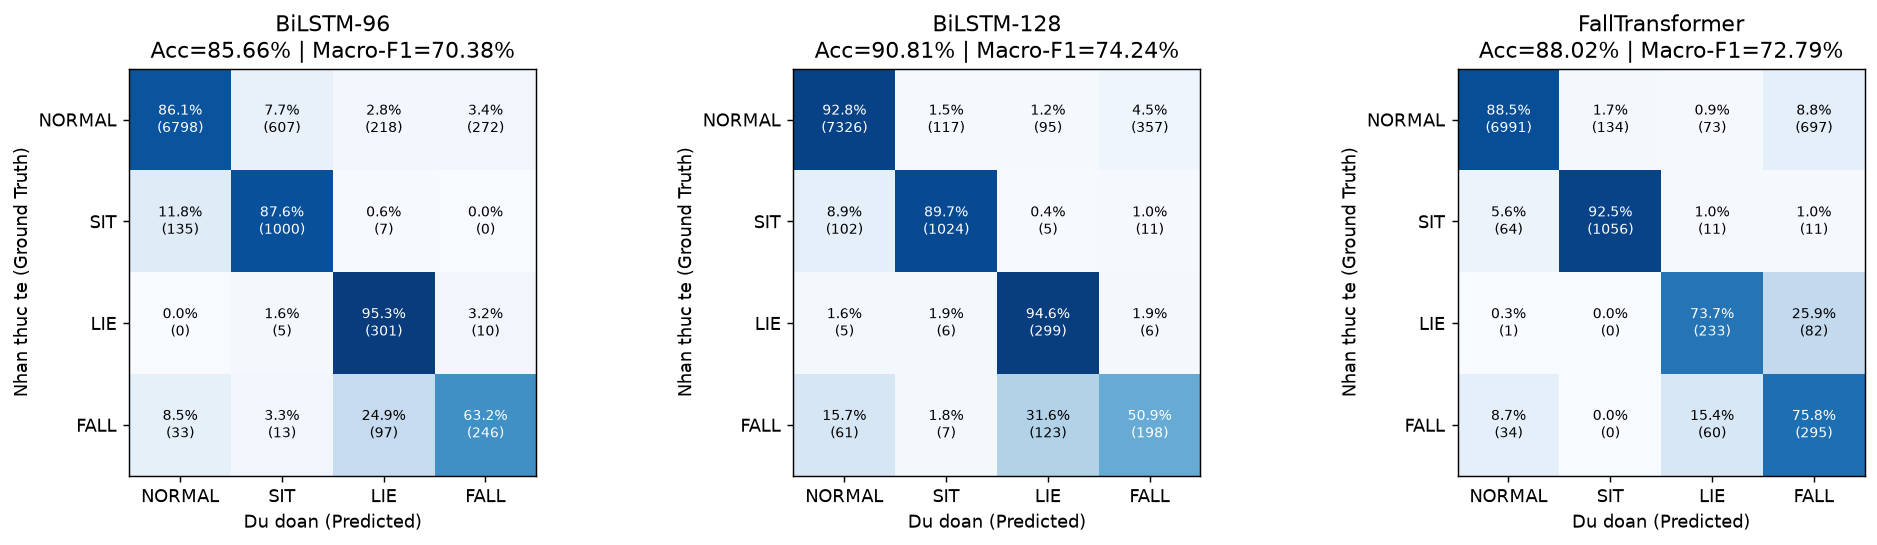

In [6]:
dl_va = DataLoader(WindowDataset(va_seqs, items_va), batch_size=128)
candidates = [
    ("BiLSTM-96 (fall_net_v3_lstm)", V3_DIR / "models" / "fall_net_v3_lstm.pth", dict(fall_thr=0.75, fall_confirm=3)),
    ("BiLSTM-128 (fall_net_v3_best)", V3_DIR / "models" / "fall_net_v3_best.pth", dict(fall_thr=0.75, fall_confirm=3)),
    ("FallTransformer (fall_net_v3_tfm)", V3_DIR / "models" / "fall_net_v3_tfm.pth", dict(fall_thr=0.75, fall_confirm=3)),
]

eval_rows = []
cms = []
for label, mpath, sm_kw in candidates:
    if not mpath.exists():
        continue
    model, ck = load_model(mpath, device)
    preds, tg = predict(model, dl_va, device)
    cm = confusion(preds, tg)
    acc = float((preds == tg).mean()) * 100
    f1s = []
    for c in range(4):
        tp = cm[c, c]
        pr = tp / max(cm[:, c].sum(), 1)
        rc = tp / max(cm[c].sum(), 1)
        f1s.append(2 * pr * rc / max(pr + rc, 1e-9))
    macro_f1 = float(np.mean(f1s)) * 100
    fall_prec = cm[FALL, FALL] / max(cm[:, FALL].sum(), 1) * 100
    fall_rec = cm[FALL, FALL] / max(cm[FALL].sum(), 1) * 100
    lie_rec = cm[LIE, LIE] / max(cm[LIE].sum(), 1) * 100

    # Mo phong cap su kien video qua AlertStateMachine
    adl_total = adl_fp = fall_total = fall_hit = 0
    lats = []
    for s in va_seqs:
        ends = list(range(FIRST_END, len(s.phase), 2))
        X_s = np.stack([window_features(s.kpts[i], s.kconf[i], s.box[i], s.present[i])
                        for i in (window_indices(e, BASE_STEP) for e in ends)])
        with torch.no_grad():
            P_s = torch.softmax(model(torch.from_numpy(X_s).to(device)), 1).cpu().numpy()
        sm = AlertStateMachine(**sm_kw)
        onsets, prev_on = [], False
        for e, p in zip(ends, P_s):
            out = sm.update(e / 30.0, p, bool(s.present[e]))
            if out["alarm"] and not prev_on:
                onsets.append(e)
            prev_on = bool(out["alarm"])
        if "fall" in s.kind:
            fall_total += 1
            post = [o for o in onsets if o >= s.fall_start - 10]
            if post:
                fall_hit += 1
                lats.append((post[0] - s.fall_start) / 30.0)
        else:
            adl_total += 1
            if onsets:
                adl_fp += 1

    ev_rec = fall_hit / max(fall_total, 1) * 100
    adl_spec = (adl_total - adl_fp) / max(adl_total, 1) * 100
    mean_lat = float(np.mean(lats)) if lats else 0.0
    eval_rows.append((label, acc, macro_f1, fall_prec, fall_rec, lie_rec, ev_rec, adl_spec, mean_lat))
    cms.append((label, acc, macro_f1, cm))

print(f"{'Mo hinh':33s} | {'Acc':>6s} | {'mF1':>6s} | {'F.Prec':>6s} | {'F.Rec':>6s} | {'L.Rec':>6s} | {'EvRec':>6s} | {'Spec':>6s} | {'Tre':>6s}")
print("-" * 105)
for r in eval_rows:
    print(f"{r[0]:33s} | {r[1]:5.2f}% | {r[2]:5.2f}% | {r[3]:5.2f}% | {r[4]:5.2f}% | {r[5]:5.2f}% | {r[6]:5.2f}% | {r[7]:5.2f}% | {r[8]:5.2f}s")

fig, axes = plt.subplots(1, len(cms), figsize=(5.2 * len(cms), 4.3))
if len(cms) == 1:
    axes = [axes]
for ax, (lbl, acc, mf1, cm) in zip(axes, cms):
    cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.set_xticklabels([c.upper() for c in CLASS_NAMES])
    ax.set_yticklabels([c.upper() for c in CLASS_NAMES])
    ax.set_xlabel("Du doan (Predicted)")
    ax.set_ylabel("Nhan thuc te (Ground Truth)")
    ax.set_title(f"{lbl.split(' (')[0]}\nAcc={acc:.2f}% | Macro-F1={mf1:.2f}%")
    for i in range(4):
        for j in range(4):
            val = cm_norm[i, j]
            ax.text(j, i, f"{val*100:.1f}%\n({cm[i, j]})", ha="center", va="center",
                    fontsize=8, color="white" if val > 0.5 else "black")
plt.tight_layout()
plt.show()

## Phần F. Máy Trạng Thái `AlertStateMachine` & Kiểm Chứng Realtime Trên Video Thực Tế

Đầu ra xác suất tức thời tại 15 Hz được đưa qua `AlertStateMachine` (`detect_v3/fall_common.py`) gồm:
1. **EMA Smoothing (`α = 0.45`):** Làm mượt nhiễu rung khung xương từng frame.
2. **Khóa chống ngồi nhanh (`fast_upright_sit`):** Khi trục thân còn thẳng (`cos θ >= 0.78`), khung đứng dọc (`box_ar < 0.80`), `bh_ratio >= 0.25` và `p_fall < 0.90`, chuyển 45% xác suất `p_fall` sang `p_sit` và nâng ngưỡng xác nhận lên `max(thr, 0.82)` với 6 bước.
3. **Tự hủy báo động nhầm (`never_tilted auto-unlatch`):** Tự mở chốt sau `0.45s` nếu trục thân chưa từng nằm ngang (`min_cos >= 0.74` và `max_ar < 0.82`).
4. **Nhánh bắt ngã khuỵu (`slump_run`) & Giữ chốt nằm bất động:** Nâng lên **Mức 2 (Khẩn cấp)** khi nằm bất động từ `8.0s` (`immobile_s=8.0`), giữ tối thiểu `3.0s` và chỉ nhả khi đứng/ngồi dậy ổn định `1.5s`.


Ket qua chay Pipeline 4_realtime.py tren 03.mp4 (167 frames):
    0.00s ->   2.38s : NORMAL
    2.42s ->   2.45s : LIE
    2.48s ->   5.57s : FALL


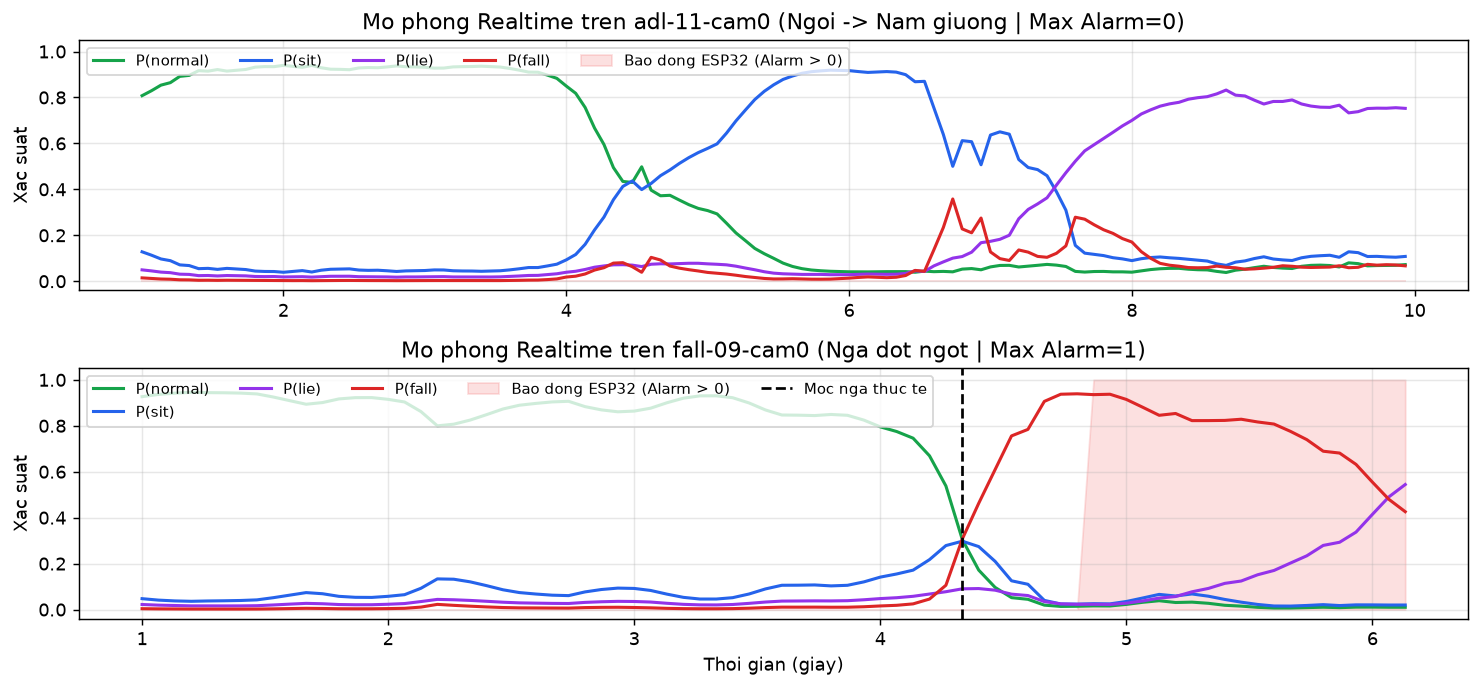

In [7]:
prod_model, _ = load_model(V3_DIR / "models" / "fall_net_v3_lstm.pth", device)

def run_sm_trace(s, thr=0.69, confirm=4):
    ends = list(range(FIRST_END, len(s.phase), 2))
    ts = [e / 30.0 for e in ends]
    X_s = np.stack([window_features(s.kpts[i], s.kconf[i], s.box[i], s.present[i])
                    for i in (window_indices(e, BASE_STEP) for e in ends)])
    with torch.no_grad():
        P_s = torch.softmax(prod_model(torch.from_numpy(X_s).to(device)), 1).cpu().numpy()
    sm = AlertStateMachine(fall_thr=thr, fall_confirm=confirm)
    alarms = [sm.update(t, p, bool(s.present[e]))["alarm"] for t, e, p in zip(ts, ends, P_s)]
    return np.array(ts), P_s, np.array(alarms)

t1, P1, A1 = run_sm_trace(s_adl)
t2, P2, A2 = run_sm_trace(s_fall)

fig, axes = plt.subplots(2, 1, figsize=(11.5, 5.4), sharex=False)
colors = ["#16a34a", "#2563eb", "#9333ea", "#dc2626"]
for ax, ts, P, A, title, s_obj in [
    (axes[0], t1, P1, A1, f"Mo phong Realtime tren {s_adl.name} (Ngoi -> Nam giuong | Max Alarm={A1.max()})", s_adl),
    (axes[1], t2, P2, A2, f"Mo phong Realtime tren {s_fall.name} (Nga dot ngot | Max Alarm={A2.max()})", s_fall),
]:
    for c_i, c_name in enumerate(CLASS_NAMES):
        ax.plot(ts, P[:, c_i], label=f"P({c_name})", color=colors[c_i], lw=1.7)
    ax.fill_between(ts, 0, (A > 0).astype(float), color="#ef4444", alpha=0.16, label="Bao dong ESP32 (Alarm > 0)")
    if s_obj.fall_start > 0:
        ax.axvline(s_obj.fall_start / 30.0, color="k", ls="--", lw=1.5, label="Moc nga thuc te")
    ax.set_ylim(-0.04, 1.05)
    ax.set_ylabel("Xac suat")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(ncol=5, fontsize=8.5, loc="upper left")
axes[1].set_xlabel("Thoi gian (giay)")
plt.tight_layout()
plt.show()

# Chay thu nghiem Pipeline hoan chinh (4_realtime.py) tren video 03.mp4 (neu co)
if demo_vid is not None:
    import importlib.util
    spec = importlib.util.spec_from_file_location("rt_v3_nb", V3_DIR / "4_realtime.py")
    rt_v3 = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(rt_v3)
    pipe = rt_v3.Pipeline(
        V3_DIR / "models" / "fall_net_v3_lstm.pth",
        str(pose_weights) if pose_weights.exists() else "yolov8n-pose.pt",
        device,
        dict(fall_thr=0.69, fall_confirm=4),
        telegram_delay=10.0,
    )
    cap = cv2.VideoCapture(str(demo_vid))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    if fps <= 1.0 or fps > 65.0:
        fps = 30.0
    seg = []
    idx = 0
    while idx < 300:
        ok, fr = cap.read()
        if not ok:
            break
        t = idx / fps
        pipe.process(fr, t)
        st = pipe.out["state"] if pipe.out else "warmup"
        if not seg or seg[-1][2] != st:
            seg.append([t, t, st])
        seg[-1][1] = t
        idx += 1
    cap.release()
    print(f"\nKet qua chay Pipeline 4_realtime.py tren {demo_vid.name} ({idx} frames):")
    for a, b, st in seg:
        print(f"  {a:6.2f}s -> {b:6.2f}s : {st.upper()}")

## Phần G. Triển Khai Thực Tế (`Raspberry Pi / PC ↔ ESP32 ↔ Flask ↔ Telegram 10s`)

Hệ thống kết nối thành vòng khép kín qua mạng LAN Wi-Fi cục bộ (`detect_v3/4_realtime.py` & `TEST_GIAO_DIEN/TEST_GIAO_DIEN.ino`):
- **Raspberry Pi / PC (AI Client + Flask Server `:5000`):** Chạy đường ống AI và mở Web Dashboard MJPEG (`/video_feed`, `/status`), đồng thời dùng luồng nền bất đồng bộ `Esp32Sender` gửi HTTP `GET http://<ESP32_IP>/set?state=...&alarm=...&persons=...` sang ESP32 (gửi ngay khi đổi trạng thái, giới hạn tối đa mỗi `0.8s` và đồng bộ định kỳ `2.5s`).
- **ESP32 (`WebServer :80`):** Nhận trạng thái từ Pi/PC, điều khiển trực tiếp màn hình **TFT 1.8" SPI ST7735 (160×128)** chuyển nền Đỏ khi ngã, bật **LED Đỏ (`GPIO 22`)** và **còi PWM loa 8Ω 2W (`GPIO 21`, `2000Hz ↔ 2800Hz`)**. ESP32 đồng thời phục vụ một trang cấu hình phần cứng cục bộ qua API `/data`.
- **Telegram Bot (`telegram_delay = 10.0s`):** Chỉ khi trạng thái ngã duy trì liên tục từ 10 giây trở lên mà người ngã chưa ngồi/đứng dậy, luồng `TelegramSender` mới chụp ảnh gốc tại hiện trường kèm mốc thời gian gửi qua Telegram Bot API.

```bash
# Chay thuc te voi Webcam 0 + ESP32 + Flask Dashboard (:5000) + Telegram 10s
python detect_v3/4_realtime.py --source 0 --esp32-ip 192.168.1.108 --telegram-delay 10 --show
```

FallNet BiLSTM-96        | Latency CPU [1,30,66]: 0.464 ms/chuoi | ~2,154 FPS
FallNet BiLSTM-128       | Latency CPU [1,30,66]: 0.485 ms/chuoi | ~2,064 FPS
FallTransformer 3L-4H    | Latency CPU [1,30,66]: 0.541 ms/chuoi | ~1,849 FPS


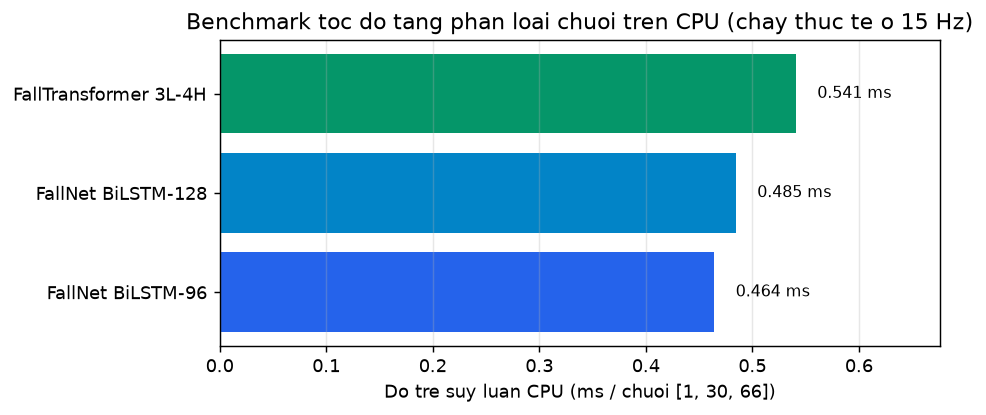

In [8]:
# Do toc do suy luan CPU thuc te cua FallNet BiLSTM-96 vs FallTransformer
x_bench = torch.randn(1, SEQ_STEPS, FEAT_DIM)
bench_res = []
for bname, bpath in [
    ("FallNet BiLSTM-96", V3_DIR / "models" / "fall_net_v3_lstm.pth"),
    ("FallNet BiLSTM-128", V3_DIR / "models" / "fall_net_v3_best.pth"),
    ("FallTransformer 3L-4H", V3_DIR / "models" / "fall_net_v3_tfm.pth"),
]:
    if not bpath.exists():
        continue
    bm, _ = load_model(bpath, torch.device("cpu"))
    with torch.no_grad():
        for _ in range(30):
            _ = bm(x_bench)
        t0 = time.perf_counter()
        iters = 300
        for _ in range(iters):
            _ = bm(x_bench)
        ms = (time.perf_counter() - t0) / iters * 1000.0
    bench_res.append((bname, ms, 1000.0 / ms))
    print(f"{bname:24s} | Latency CPU [1,30,66]: {ms:.3f} ms/chuoi | ~{1000.0/ms:,.0f} FPS")

fig, ax = plt.subplots(figsize=(7.5, 3.3))
names_b = [r[0] for r in bench_res]
lats_b = [r[1] for r in bench_res]
bars = ax.barh(names_b, lats_b, color=["#2563eb", "#0284c7", "#059669"])
ax.set_xlabel("Do tre suy luan CPU (ms / chuoi [1, 30, 66])")
ax.set_title("Benchmark toc do tang phan loai chuoi tren CPU (chay thuc te o 15 Hz)")
for bar, val in zip(bars, lats_b):
    ax.text(val + 0.02, bar.get_y() + bar.get_height()/2, f"{val:.3f} ms", va="center", fontsize=9)
ax.set_xlim(0, max(lats_b) * 1.25)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Tổng Kết Toàn Bộ Quy Trình Từ A Đến Z

Qua notebook thực hành khép kín từ bước chuẩn bị dữ liệu đến kiểm thử thời gian thực, toàn bộ quy trình hình thành phiên bản hoàn chỉnh `detect_v3` đã được chứng minh và tái lập minh bạch:
- **Dữ liệu sạch tuyệt đối (`Zero Data Leakage`):** Hợp nhất 6.250 chuỗi (870.062 khung hình skeleton) từ 6 nguồn công khai và tự quay, phân chia Train (6.163 chuỗi) và Validation (87 chuỗi / 16 nhóm độc lập) với **0 nhóm trùng lặp**. Kết hợp gán nhãn tách pha `FALL` vs. `LIE`, bổ sung 372.439 `Frozen Windows` (giữ `FALL = 0`), tăng cường khung xương trực tiếp và `Hard-Negative Mining` tại epoch 12 & 24.
- **Đường ống Lai Đa tầng (`YOLOv8n-pose + 7 Bộ lọc + 66 Đặc trưng + BiLSTM/Transformer`):** Hạ ngưỡng `INFER_CONF = 0.08` tại `INFER_IMGSZ = 640` giúp bắt được người nằm xa trên CCTV gắn trần mà vẫn triệt tiêu khớp giả vật tĩnh nhờ 7 bộ lọc giải phẫu và `PoseTracker`. Tensor 66 chiều tại 15 Hz giúp hai nhánh học sâu chỉ tiêu tốn dưới `1 ms` CPU/chuỗi, trong đó `FallNet BiLSTM-96` (`fall_net_v3_lstm.pth`) tối ưu chống báo giả (**ADL Specificity = 85,29%**, độ trễ trung bình dưới `1s`) còn `FallTransformer` tối ưu độ nhạy sự kiện ngã đa góc (**Event Fall Recall = 73,58%**).
- **Hoàn thiện Edge AI – IoT:** Khi `AlertStateMachine` xác nhận ngã (vượt qua lớp khóa chống ngồi nhanh và mở chốt tự động `0.45s`), bộ não AI lập tức đẩy lệnh HTTP `GET /set` tới mạch nhúng ESP32 để bật màn hình Đỏ ST7735, LED D22 và còi PWM `2000↔2800 Hz`, đồng thời chỉ chụp ảnh gửi Telegram sau độ trễ an toàn `10,0s` nếu nạn nhân vẫn chưa tự ngồi hoặc đứng dậy.